# Partie I : Exploration, preprocessing, non supervisé

**Objectif de ce notebook** : charger le dataset *Myocardial infarction complications* et produire trois objets, utilisés ensuite par tout le groupe :

| Objet | Contenu |
|---|---|
| `y` | la cible : le patient est-il décédé (1) ou a-t-il survécu (0) ? |
| `X_admission` | les variables connues **à l'admission** à l'hôpital |
| `X_jour3` | les variables connues **au 3ᵉ jour** (toutes les variables d'entrée) |

**Pourquoi deux jeux de variables ?** On veut savoir si l'on peut prédire les complications dès l'arrivée du patient, puis si les informations recueillies pendant 3 jours améliorent la prédiction. Utiliser au jour 0 une information qui n'existe qu'au jour 3 serait de la **fuite de données** (*data leakage*) : le modèle paraîtrait excellent mais serait inutilisable en pratique.

Le dataset contient 1700 patients, 111 variables d'entrée (*features*) et 12 complications possibles.

## I - Chargement des données

### I.1 - Import des bibliothèques

In [31]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

### I.2 - Chargement du fichier CSV

Le fichier doit se trouver à côté du notebook ou dans un dossier `data/`. La cellule ci-dessous cherche à plusieurs endroits et affiche un message clair si elle ne trouve rien (c'était la cause du `FileNotFoundError`).

On utilise `index_col="ID"` : la colonne `ID` identifie le patient, ce n'est pas une variable à donner au modèle.

In [32]:
NAME_FILES = "Myocardial_infarction_complications_Database.csv"
PATH_FILES = [NAME_FILES, os.path.join("data", NAME_FILES), os.path.join("..", "data", NAME_FILES)]

chemin = next((c for c in PATH_FILES if os.path.exists(c)), None)
if chemin is None:
    raise FileNotFoundError(
        f"{NAME_FILES} introuvable. Cherché dans : {PATH_FILES}. "
        "Copiez le CSV dans le dossier du notebook ou dans data/."
    )

df = pd.read_csv(chemin, index_col="ID")
print("Fichier chargé :", chemin)
print("Dimensions :", df.shape)   # attendu : (1700, 123) = 111 entrées + 12 complications

Fichier chargé : data/Myocardial_infarction_complications_Database.csv
Dimensions : (1700, 123)


> ⚠️ **Attention** : Les valeurs manquantes sont des **cases vides** dans le CSV, que pandas lit directement comme `NaN` (pas besoin de `na_values="?"`).



## II - Exploration des donnnées

### II.1 - Séparation des variables d'entrée et de complications

Les 12 dernières colonnes sont des **complications** (ce qu'on veut prédire). Toutes les autres sont des variables d'entrée.

On les sélectionne **par leur nom** et non par leur position (`iloc[:, 2:113]`). Avec un numéro, un décalage d'une colonne passe inaperçu et peut mettre une complication dans `X`, ce qui donne une fuite de données.

In [33]:
COMPLICATIONS = [
    "FIBR_PREDS",  # fibrillation auriculaire
    "PREDS_TAH",   # tachycardie supraventriculaire
    "JELUD_TAH",   # tachycardie ventriculaire
    "FIBR_JELUD",  # fibrillation ventriculaire
    "A_V_BLOK",    # bloc auriculo-ventriculaire du 3e degré
    "OTEK_LANC",   # œdème pulmonaire
    "RAZRIV",      # rupture myocardique
    "DRESSLER",    # syndrome de Dressler
    "ZSN",         # insuffisance cardiaque chronique
    "REC_IM",      # récidive d'infarctus
    "P_IM_STEN",   # angine post-infarctus
    "LET_IS",      # issue létale : 0 = survie, 1 à 7 = cause du décès
]

X_all = df.drop(columns=COMPLICATIONS)


### II.2 - Définion La cible `y` : `LET_IS` décès ou survie

`LET_IS` vaut 0 si le patient survit, et de 1 à 7 selon la cause du décès (1 choc cardiogénique, 2 œdème pulmonaire, 3 rupture myocardique, 4 aggravation de l'insuffisance cardiaque, 5 thromboembolie, 6 asystolie, 7 fibrillation ventriculaire).

On la **binarise** : 0 = survie, 1 = décès (quelle qu'en soit la cause). On obtient un problème de classification binaire.

Répartition de la variable LET_IS
LET_IS
survie    1429
décès      271
Name: count, dtype: int64
Proportion de décès : 15.9%


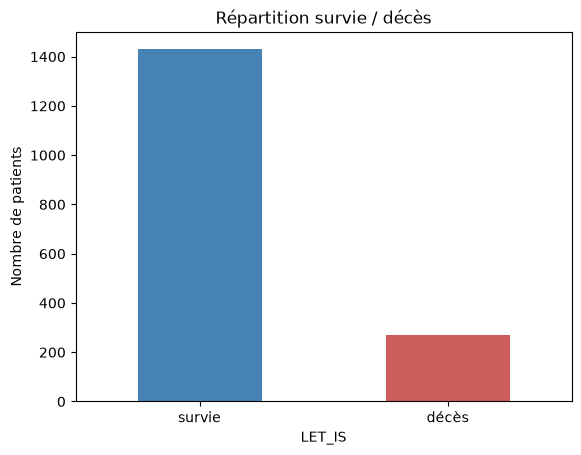

In [34]:
y = df["LET_IS"]

# On binarise la variable letale : 0 = survie, 1 = décès

for i in range(len(y)): 
    if y.iloc[i] > 0: 
        y.iloc[i] = 1

print("Répartition de la variable LET_IS")
print(y.value_counts().rename({0: "survie", 1: "décès"}))
print("Proportion de décès :", f"{y.mean():.1%}")

y.value_counts().rename({0: "survie", 1: "décès"}).plot(kind="bar", color=["steelblue", "indianred"])
plt.title("Répartition survie / décès")
plt.ylabel("Nombre de patients")
plt.xticks(rotation=0)
plt.show()

**À retenir** : les classes sont **déséquilibrées** (les décès sont une minorité). L'*accuracy* ne suffira donc pas : un modèle qui prédit toujours « survie » aurait un score élevé tout en étant inutile. On utilisera le recall.

L'objectif de notre modèle est de rater le moins de decès possible, nous allons donc porter une attention particulière au recall.

### II.3 - Séparation des variables admission et après 3 jours de soin?

Les colonnes suivent l'ordre chronologique du dossier médical. Certaines ne sont connues que **plus tard** dans l'hospitalisation :

| Groupe | Colonnes | Moment où l'information existe |
|---|---|---|
| Antécédents, ECG, biologie, délai | `AGE` … `TIME_B_S` | à l'admission |
| Traitements des urgences | `NA_KB`, `NOT_NA_KB`, `LID_KB`, `NITR_S` | à l'admission (équipe d'urgence) |
| Douleur récurrente | `R_AB_1_n`, `R_AB_2_n`, `R_AB_3_n` | `_1_` premières heures, `_2_` jour 2, `_3_` jour 3 |
| Opioïdes en soins intensifs | `NA_R_1_n`, `NA_R_2_n`, `NA_R_3_n` | `_1_` premières heures, `_2_` jour 2, `_3_` jour 3 | |
| Anti-inflammatoires en soins intensifs | `NOT_NA_1_n`, `NOT_NA_2_n`, `NOT_NA_3_n` | `_1_` premières heures, `_2_` jour 2, `_3_` jour 3 | |
| Autres traitements en soins intensifs | `LID_S_n`, `B_BLOK_S_n`, `ANT_CA_S_n`, `GEPAR_S_n`, `ASP_S_n`, `TIKL_S_n`, `TRENT_S_n` | pendant le séjour (moment exact à vérifier) |


In [35]:
# Colonnes dont la valeur dépend de ce qui se passe APRÈS l'arrivée (jours 1 à 3)
COLONNES_APRES_ADMISSION = [
    "R_AB_1_n", "R_AB_2_n", "R_AB_3_n",          # récidive de la douleur
    "NA_R_1_n", "NA_R_2_n", "NA_R_3_n",          # opioïdes en soins intensifs
    "NOT_NA_1_n", "NOT_NA_2_n", "NOT_NA_3_n",    # anti-inflammatoires en soins intensifs
]

# Traitements en soins intensifs dont le moment exact est incertain.
# Si STRICT_ADMISSION = True, on les retire aussi du scénario « admission ».

COLONNES_SOINS_INTENSIFS_INCERTAINES = [
    "LID_S_n", "B_BLOK_S_n", "ANT_CA_S_n", "GEPAR_S_n", "ASP_S_n", "TIKL_S_n", "TRENT_S_n",
]

STRICT_ADMISSION = True  # à décider en groupe

a_retirer = list(COLONNES_APRES_ADMISSION)
if STRICT_ADMISSION:
    a_retirer += COLONNES_SOINS_INTENSIFS_INCERTAINES

### II.4 - Construction des dataframe `X_admission` et `X_jour3`

- `X_jour3` : toutes les variables d'entrée (information complète au 3ᵉ jour).
- `X_admission` : les mêmes, moins les colonnes de la cellule précédente.

On garde des **DataFrames** (avec les noms de colonnes) et on ne les convertit pas en tableaux numpy : sans les noms, on ne peut plus interpréter les résultats (importance des variables, SHAP, arbre de décision).

In [36]:
X_jour3 = X_all.copy()
X_admission = X_all.drop(columns=a_retirer)

print("X_jour3     :", X_jour3.shape)
print("X_admission :", X_admission.shape)
print("Colonnes retirées pour l'admission :", len(a_retirer))

X_jour3     : (1700, 111)
X_admission : (1700, 95)
Colonnes retirées pour l'admission : 16


### II.5 - Définition des types de variables de `X_admission` et `X_jour3`

On cherche a donnée un type chacune des variables qui vont nous servir à entrainer le modèle. On distingue 3 types de variables : 
- `binaire` pour les variables binaire
- `ordinal` (on place le seuil ordinale à 10)
- `continue`

On affiche également le pourcentage manquant pour chaque colonne

In [37]:
SEUIL_ORDINALE = 10  # au plus 10 modalités entières distinctes -> ordinale

def type_variable(s):
    """Classe une colonne en 'binaire', 'ordinale' ou 'continue' (NaN ignorés)."""
    valeurs = s.dropna().unique()
    if len(valeurs) <= 2:
        return "binaire"
    if np.all(valeurs == np.round(valeurs)) and len(valeurs) <= SEUIL_ORDINALE:
        return "ordinale"
    return "continue"

def resume_par_type(X):
    return pd.DataFrame({
        "type": X.apply(type_variable),
        "nb_modalites": X.nunique(),
        "min": X.min(),
        "max": X.max(),
        "moyenne": X.mean(),
        "% manquants": X.isna().mean() * 100,
    })

resume_all = resume_par_type(X_all)

print(resume_all["type"].value_counts())

for t in ["binaire", "ordinale", "continue"]:
    print(f"\n=== Variables {t}s ===")
    display(resume_all[resume_all["type"] == t].drop(columns="type"))
    

type
binaire     78
ordinale    21
continue    12
Name: count, dtype: int64

=== Variables binaires ===


,nb_modalites,min,max,moyenne,% manquants
SEX,2,0.0,1.0,0.626471,0.000000
IBS_NASL,2,0.0,1.0,0.375000,95.764706
SIM_GIPERT,2,0.0,1.0,0.033688,0.470588
nr_11,2,0.0,1.0,0.025015,1.235294
nr_01,2,0.0,1.0,0.002382,1.235294
...,...,...,...,...,...
ANT_CA_S_n,2,0.0,1.0,0.666864,0.764706
GEPAR_S_n,2,0.0,1.0,0.714795,1.000000
ASP_S_n,2,0.0,1.0,0.743910,1.000000
TIKL_S_n,2,0.0,1.0,0.017815,0.941176



=== Variables ordinales ===


,nb_modalites,min,max,moyenne,% manquants
INF_ANAM,4,0.0,3.0,0.554835,0.235294
STENOK_AN,7,0.0,6.0,2.316186,6.235294
FK_STENOK,5,0.0,4.0,1.205286,4.294118
IBS_POST,3,0.0,2.0,1.160703,3.000000
GB,4,0.0,3.0,1.393258,0.529412
DLIT_AG,8,0.0,7.0,3.340220,14.588235
ZSN_A,5,0.0,4.0,0.194411,3.176471
ant_im,5,0.0,4.0,1.570810,4.882353
lat_im,5,0.0,4.0,0.861728,4.705882
inf_im,5,0.0,4.0,1.014815,4.705882



=== Variables continues ===


,nb_modalites,min,max,moyenne,% manquants
AGE,62,26.00,92.00,61.856974,0.470588
S_AD_KBRIG,30,0.00,260.00,136.907051,63.294118
D_AD_KBRIG,21,0.00,190.00,81.394231,63.294118
S_AD_ORIT,32,0.00,260.00,134.588276,15.705882
D_AD_ORIT,20,0.00,190.00,82.749477,15.705882
K_BLOOD,51,2.30,8.20,4.191422,21.823529
NA_BLOOD,40,117.00,169.00,136.550943,22.058824
ALT_BLOOD,69,0.03,3.00,0.481455,16.705882
AST_BLOOD,58,0.04,2.15,0.263717,16.764706
KFK_BLOOD,4,1.20,3.60,2.000000,99.764706


### II.6 Valeur manquante par patient 

On affiche ici le pourcentage de valeur manquant par patient (par ligne)

In [38]:
# Pourcentage de valeurs manquantes pour chaque patient (chaque ligne de X_all)

resume_patient = (
    X_all.isna().mean(axis=1)
    .mul(100)
    .round(2)
    .rename("% manquants")
    .to_frame()
)

display(resume_patient.head())

,% manquants
ID,
1,8.11
2,2.70
3,2.70
4,8.11
5,2.70


### II.7 Étude des données sur les différentes causes de decès / survivant

In [39]:
n_surv, n_deces = (y == 0).sum(), (y == 1).sum()
print(f"Survie : {n_surv} ({n_surv/len(y):.1%}) | Décès : {n_deces} ({n_deces/len(y):.1%})")
print(f"Ratio : 1 décès pour {n_surv/n_deces:.1f} survivants")

Survie : 1429 (84.1%) | Décès : 271 (15.9%)
Ratio : 1 décès pour 5.3 survivants


Cause de décès (sur la database avant la bianarisation de le colonnes "LET_IS")

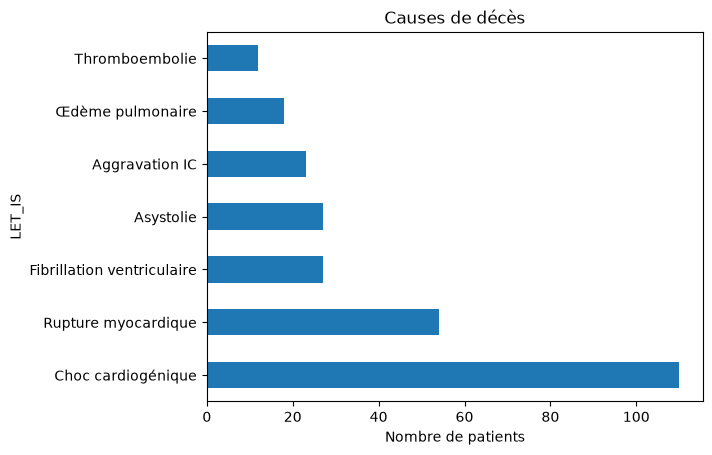

In [40]:
causes = {1: "Choc cardiogénique", 2: "Œdème pulmonaire", 3: "Rupture myocardique",
          4: "Aggravation IC", 5: "Thromboembolie", 6: "Asystolie", 7: "Fibrillation ventriculaire"}
df.loc[df["LET_IS"] > 0, "LET_IS"].map(causes).value_counts().plot(kind="barh")
plt.xlabel("Nombre de patients"); plt.title("Causes de décès"); plt.show()

## III - Séparation du jeu de donnée (train/test) et étude des données

On réalise un étude des données sur le jeu de donnée train pour éviter le dataleak du jeu de données test. L'objectif de cette partie est de comprendre que sont les données qui sont intéressante pour notre analyse.

### III.1 - Séparation du jeu de données en train / test

In [41]:
from sklearn.model_selection import train_test_split

SEED = 42  # fixe le découpage : tout le groupe obtient les mêmes patients dans le train et le test

# 1. On sépare les PATIENTS (leurs identifiants), pas les tableaux.
#    Ainsi X_admission et X_jour3 ont exactement les mêmes patients de test.
idx_train, idx_test = train_test_split(
    y.index,
    test_size=0.2,    # 20 % des patients pour le test
    stratify=y,       # même proportion de décès dans le train et le test
    random_state=SEED,
)

# 2. On applique ce découpage aux deux scénarios et à la cible
X_adm_train, X_adm_test = X_admission.loc[idx_train], X_admission.loc[idx_test]
X_j3_train,  X_j3_test  = X_jour3.loc[idx_train],     X_jour3.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]

# 3. Vérifications
print(f"Train : {len(idx_train)} patients, {y_train.sum()} décès ({y_train.mean():.1%})")
print(f"Test  : {len(idx_test)} patients, {y_test.sum()} décès ({y_test.mean():.1%})")

assert set(idx_train).isdisjoint(idx_test), "Des patients sont à la fois dans le train et le test"
assert X_adm_train.index.equals(X_j3_train.index) and X_adm_test.index.equals(X_j3_test.index)

Train : 1360 patients, 217 décès (16.0%)
Test  : 340 patients, 54 décès (15.9%)


### III.2 - Études des données (exemple)

Ici nous allons chercher à visualiser les données continue, pour identifier cette qui sont correlé entre elles ainsi que celle qui diffère entre les patients survivant ou décédés. L'objectif ici est d'isoler les données qui vont nous permettre d'entrainer le modèle.

KFK_BLOOD     99.7
S_AD_KBRIG    63.5
AST_BLOOD     16.9
ALT_BLOOD     16.8
S_AD_ORIT     16.2
D_AD_ORIT     16.2
ROE           12.4
L_BLOOD        7.6
AGE            0.4


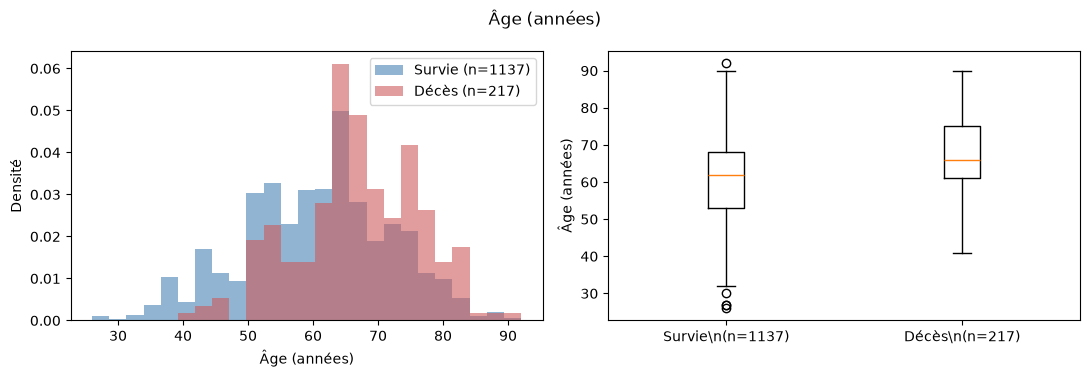

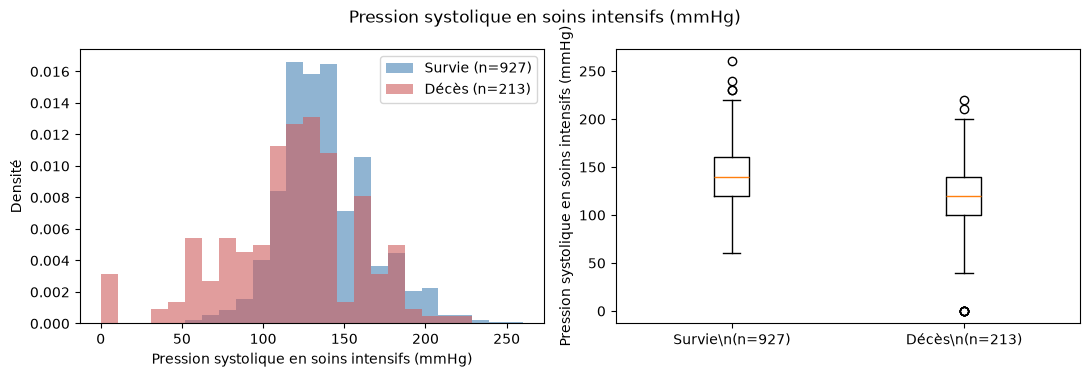

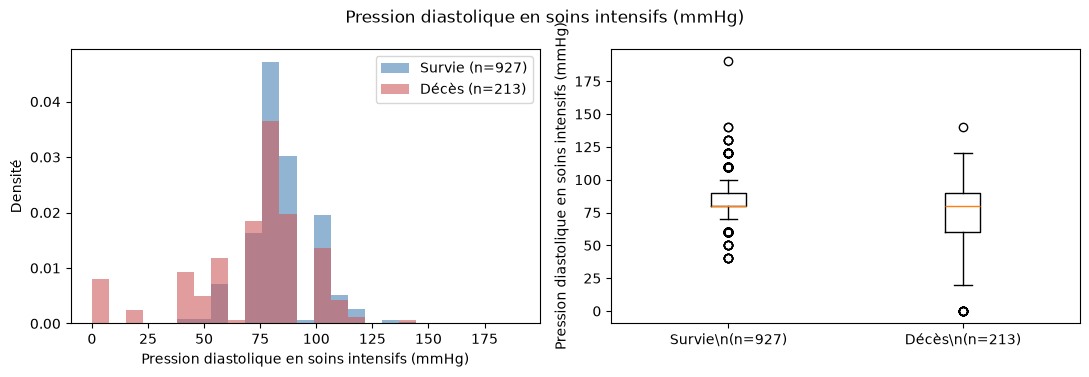

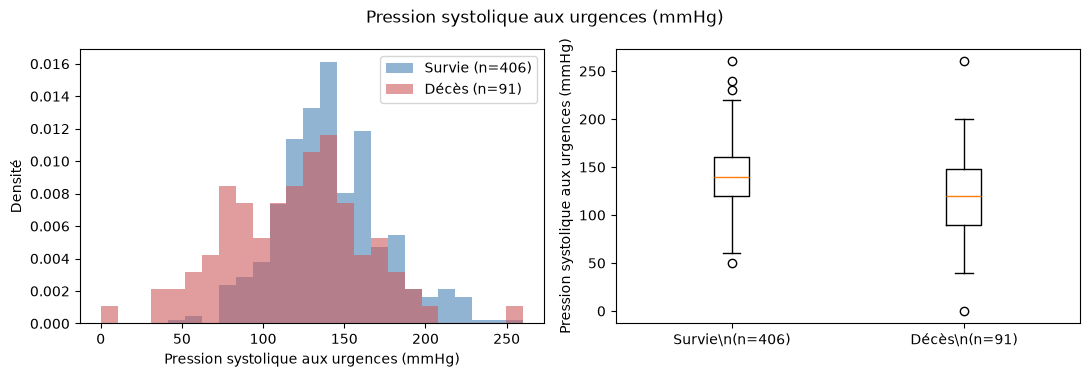

/Users/maximgasnier/miniforge3/envs/SDD/lib/python3.12/site-packages/numpy/lib/_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges


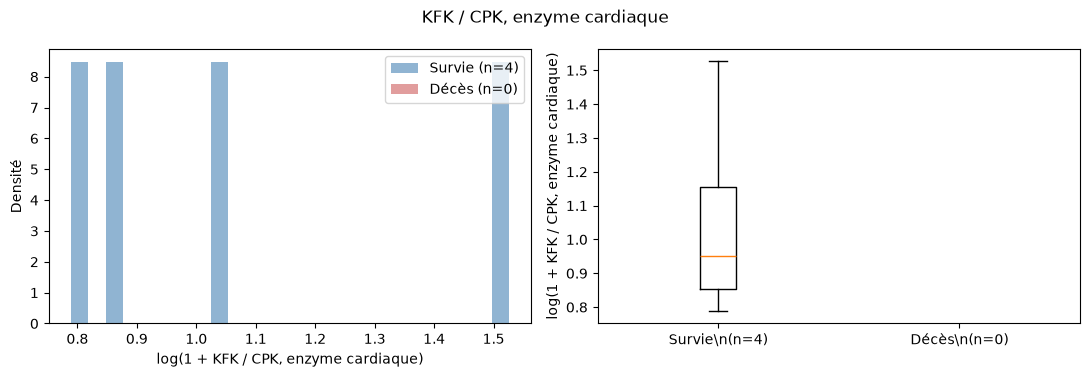

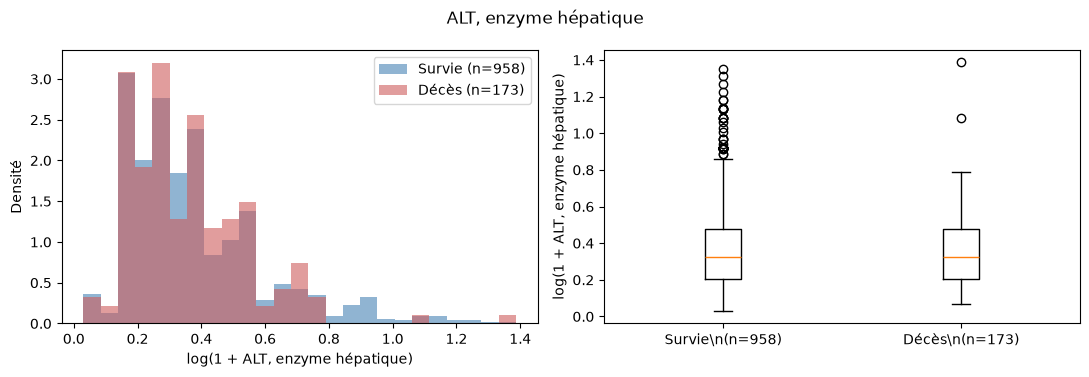

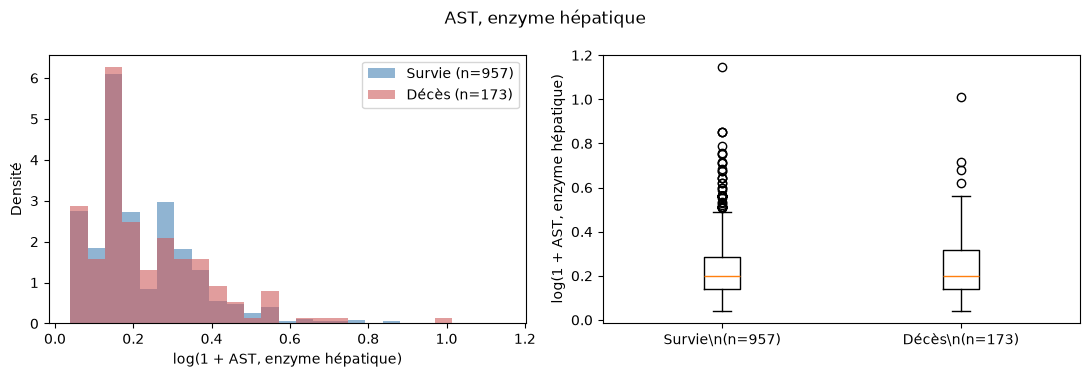

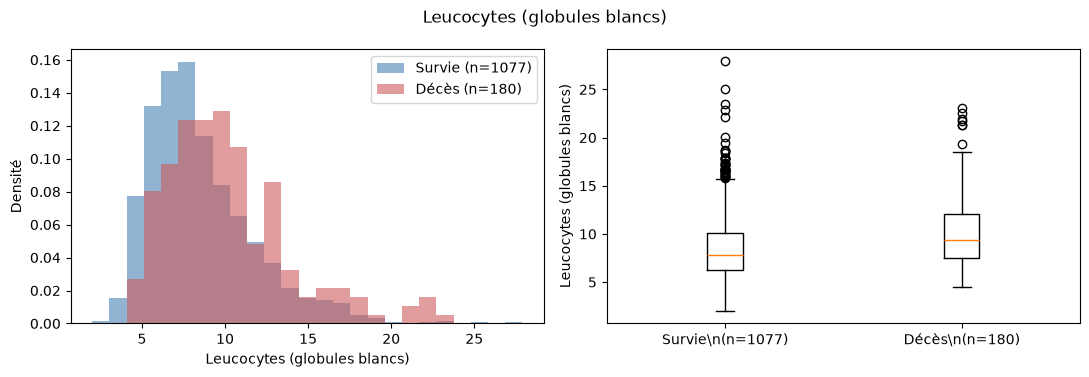

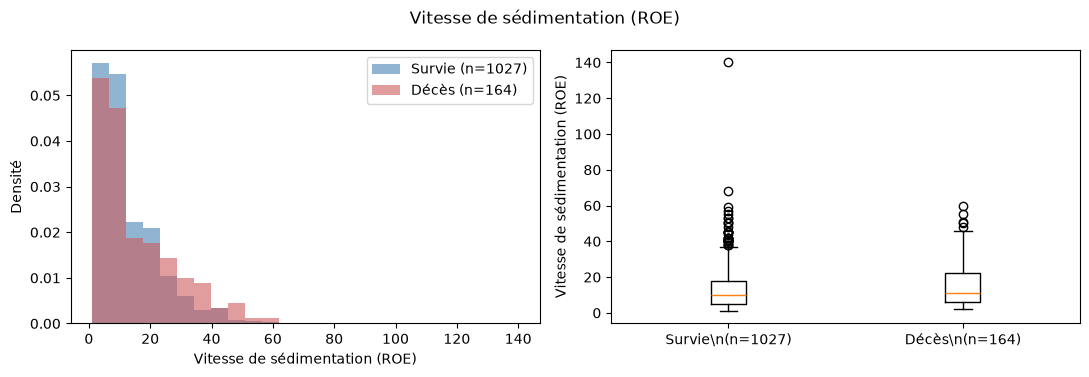

groupe            Décès  Survie
AGE        count  217.0  1137.0
           25%     61.0    53.0
           50%     66.0    62.0
           75%     75.0    68.0
S_AD_ORIT  count  213.0   927.0
           25%    100.0   120.0
           50%    120.0   140.0
           75%    140.0   160.0
D_AD_ORIT  count  213.0   927.0
           25%     60.0    80.0
           50%     80.0    80.0
           75%     90.0    90.0
S_AD_KBRIG count   91.0   406.0
           25%     90.0   120.0
           50%    120.0   140.0
           75%    147.5   160.0
KFK_BLOOD  count    0.0     4.0
           25%      NaN     1.3
           50%      NaN     1.6
           75%      NaN     2.2
ALT_BLOOD  count  173.0   958.0
           25%      0.2     0.2
           50%      0.4     0.4
           75%      0.6     0.6
AST_BLOOD  count  173.0   957.0
           25%      0.2     0.2
           50%      0.2     0.2
           75%      0.4     0.3
L_BLOOD    count  180.0  1077.0
           25%      7.5     6.3
        

In [42]:
# Tableau d'exploration : variables du jour 3 + groupe (survie / décès), train uniquement
exploration = X_j3_train.copy()
exploration["groupe"] = y_train.map({0: "Survie", 1: "Décès"})

COULEURS = {"Survie": "steelblue", "Décès": "indianred"}

# colonne : (libellé, échelle logarithmique ?)
# Les unités sont à vérifier dans la description UCI.
VARIABLES = {
    "AGE":        ("Âge (années)", False),
    "S_AD_ORIT":  ("Pression systolique en soins intensifs (mmHg)", False),
    "D_AD_ORIT":  ("Pression diastolique en soins intensifs (mmHg)", False),
    "S_AD_KBRIG": ("Pression systolique aux urgences (mmHg)", False),
    "KFK_BLOOD":  ("KFK / CPK, enzyme cardiaque", True),
    "ALT_BLOOD":  ("ALT, enzyme hépatique", True),
    "AST_BLOOD":  ("AST, enzyme hépatique", True),
    "L_BLOOD":    ("Leucocytes (globules blancs)", False),
    "ROE":        ("Vitesse de sédimentation (ROE)", False),
}

def comparer(col, libelle, log=False):
    """Histogramme + boxplot de `col`, survivants contre décédés."""
    donnees = {g: exploration.loc[exploration["groupe"] == g, col].dropna()
               for g in ["Survie", "Décès"]}
    if log:  # variables très asymétriques : on passe à log(1 + x) pour y voir quelque chose
        donnees = {g: np.log1p(v) for g, v in donnees.items()}
    xlabel = f"log(1 + {libelle})" if log else libelle

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))

    # Histogramme : mêmes classes pour les deux groupes, et density=True car
    # les décès sont beaucoup moins nombreux (sinon leur barre serait invisible)
    tout = np.concatenate([v.values for v in donnees.values()])
    bins = np.histogram_bin_edges(tout, bins=25)
    for g, v in donnees.items():
        ax1.hist(v, bins=bins, density=True, alpha=0.6, color=COULEURS[g],
                 label=f"{g} (n={len(v)})")
    ax1.set_xlabel(xlabel); ax1.set_ylabel("Densité"); ax1.legend()

    # Boxplot avec l'effectif de chaque groupe
    ax2.boxplot([donnees["Survie"], donnees["Décès"]], showfliers=True)
    ax2.set_xticklabels([f"{g}\\n(n={len(donnees[g])})" for g in ["Survie", "Décès"]])
    ax2.set_ylabel(xlabel)

    fig.suptitle(libelle)
    plt.tight_layout()
    plt.show()

# 1. Regarder d'abord combien de valeurs manquantes (et donc combien de patients exploitables)
cols = list(VARIABLES)
print((exploration[cols].isna().mean() * 100).round(1).sort_values(ascending=False).to_string())

# 2. Un couple de graphiques par variable
for col, (libelle, log) in VARIABLES.items():
    comparer(col, libelle, log)

# 3. Tableau récapitulatif : médiane et quartiles par groupe
resume = exploration.groupby("groupe")[cols].describe().T.loc[(slice(None), ["count", "25%", "50%", "75%"]), :]
print(resume.round(1))

### Objectif

Nous cherchons à savoir si certaines *features* se comportent différemment chez les patients décédés et chez les survivants.

Pour chaque variable, nous traçons un histogramme (forme de la distribution) et un boxplot (comparaison des médianes et des dispersions). Quatre choix méthodologiques sont à noter :

- **Jeu d'entraînement uniquement** : les graphiques servent à prendre des décisions de preprocessing. Utiliser le jeu de test pour cela fausserait l'évaluation finale.
- **Histogrammes normalisés (densité)** : les décès sont beaucoup moins nombreux que les survies. Sans normalisation, la distribution des décès serait invisible.

- **Effectif affiché** sur chaque graphique : la comparaison n'a de sens que si chaque groupe contient assez de patients.

### Valeurs manquantes

Le pourcentage de valeurs manquantes varie fortement d'une variable à l'autre : [À REMPLIR : % pour AGE, pression, KFK, ALT/AST, leucocytes]. Une valeur manquante signifie souvent qu'un examen n'a pas été réalisé, et pas seulement qu'une saisie a été oubliée. Pour la variable [À REMPLIR : la plus incomplète], seuls [À REMPLIR : n] patients sont renseignés dans le train, dont [À REMPLIR : n] décédés : la comparaison est [possible / peu fiable / impossible], et nous [ne l'interprétons pas / l'interprétons avec prudence].

### Âge

Les patients décédés sont plus âgés que les survivants : l'âge médian est de 66 ans chez les décédés contre 62 ans chez les survivants. Les deux distributions se chevauchent  modérément.
L'Âge est une caractéristique interessante pour notre modèle.
Nous disposons également de cette valeur pour le cas des patients admis au urgence, nous retrouvons un écart à la médiane qui est similaire.

### Pression systolique

À l'entrée en soins intensifs, la pression systolique médiane est de 120 mmHg chez les survivants et de 100 mmHg chez les décédés. La différence est nette.
La pression systolique est une caractéristique interessante pour notre modèle. 
Nous disposons également de cette valeur pour le cas des patients admis au urgence, nous retrouvons un écart à la médiane qui est similaire.

### KFK (enzyme cardiaque)

La KFK (CPK) est une enzyme libérée par le muscle cardiaque lorsqu'il est lésé : elle est généralement associée à l'étendue de la nécrose. La variable est renseignée pour trop peu de patient elle n'est donc pas intéressante pour notre analyse.

### ALT et AST (enzymes hépatiques)

Ces enzymes reflètent l'état du foie, mais elles augmentent aussi lors de lésions cardiaques. Leurs distributions est similaire pour les cas de décès et de survie. Ces variables ne sont donc pas interessante pour notre analyse.

### Leucocytes

Les leucocytes (globules blancs) augmentent en cas de réaction inflammatoire. Le nombre médian est de 7,8 chez les survivants et de 9,4 chez les décédés. Cette caractéristique est donc intéressante pour notre analyse.

### Valeurs extrêmes

Pour l'instant nous avons pris la decision de ne pas supprimer les valeurs extrèmes, car elles peuvent correspondre à des cas réel de patient. Nous verrons par la suite si il intéressant de les traiter.

### Synthèse

- Les variables qui semblent le mieux distinguer les deux groupes sont age, pression systolique, leucocyte.
- Les variables qui semblent peu discriminantes sont KFK, ALT, AST.
- Une variable à créer lors du *feature engineering* : la pression pulsée (S_AD − D_AD).

### III.3 - Calcul de la matrice de correlation

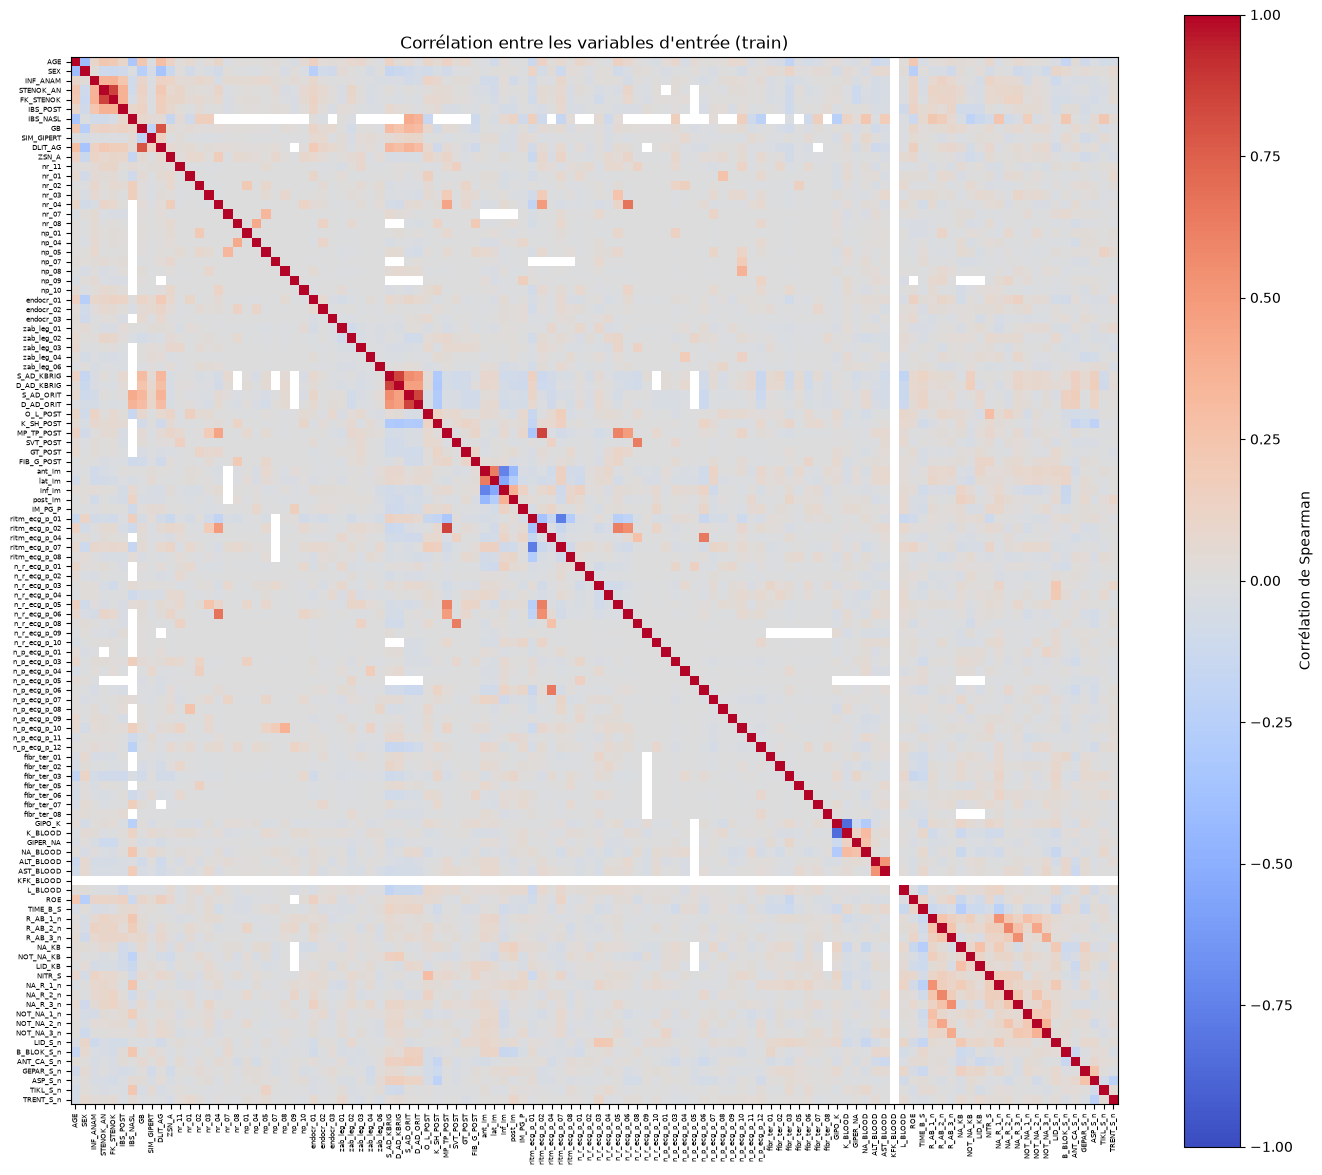

8 paires avec |corrélation| >= 0.7
STENOK_AN      FK_STENOK        0.86
S_AD_ORIT      D_AD_ORIT        0.85
GIPO_K         K_BLOOD         -0.85
S_AD_KBRIG     D_AD_KBRIG       0.84
MP_TP_POST     ritm_ecg_p_02    0.84
GB             DLIT_AG          0.79
ritm_ecg_p_01  ritm_ecg_p_07   -0.77
ant_im         inf_im          -0.74


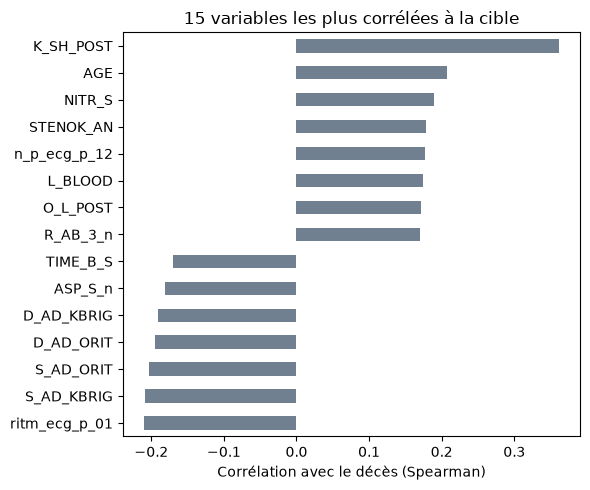

In [28]:
# 1. Données : toutes les features du jour 3, train uniquement.
#    On retire les colonnes constantes (une corrélation avec elles n'est pas définie).
donnees = X_j3_train.copy()
donnees = donnees.loc[:, donnees.nunique() > 1]

# 2. Matrice de corrélation de Spearman, calculée sur les patients où les deux variables sont connues.
#    min_periods : si moins de 30 patients ont les deux valeurs, la corrélation reste vide (NaN).
corr = donnees.corr(method="spearman", min_periods=30)

# 3. Heatmap
fig, ax = plt.subplots(figsize=(14, 12))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90, fontsize=5)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns, fontsize=5)
fig.colorbar(im, ax=ax, label="Corrélation de Spearman")
ax.set_title("Corrélation entre les variables d'entrée (train)")
plt.tight_layout()
plt.show()

# 4. Paires de variables fortement corrélées (on ne garde que le triangle supérieur pour éviter les doublons)
SEUIL = 0.7
haut = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
paires = haut[haut.abs() >= SEUIL].sort_values(key=abs, ascending=False)
print(f"{len(paires)} paires avec |corrélation| >= {SEUIL}")
print(paires.round(2).to_string())

# 5. Corrélation de chaque variable avec la cible (décès)
avec_cible = donnees.apply(lambda col: col.corr(y_train, method="spearman", min_periods=30))
top = avec_cible.reindex(avec_cible.abs().sort_values(ascending=False).index).head(15)

top.sort_values().plot(kind="barh", figsize=(6, 5), color="slategray")
plt.xlabel("Corrélation avec le décès (Spearman)")
plt.title("15 variables les plus corrélées à la cible")
plt.tight_layout()
plt.show()

## IV - Preprocessing des données

In [45]:
SEUIL_NA = 0.4  # on supprime les colonnes avec plus de 40 % de valeurs manquantes

def supprimer_colonnes_vides(df, seuil=SEUIL_NA, nom="dataset"):
    """Supprime les colonnes dont le taux de NA dépasse `seuil`.
    Retourne le DataFrame nettoyé et la liste des colonnes supprimées."""
    df = df.replace(["", "?", "unknown", "N/A"], np.nan)  # NA déguisés

    taux_na = df.isna().mean().sort_values(ascending=False)

    recap = pd.DataFrame({
        "nb_manquants": df.isna().sum(),
        "taux_manquants (%)": (df.isna().mean() * 100).round(2)
    }).sort_values("taux_manquants (%)", ascending=False)

    print(f"===== {nom} =====")
    print(recap[recap["nb_manquants"] > 0], "\n")

    cols_a_supprimer = taux_na[taux_na > seuil].index.tolist()

    df_clean = df.drop(columns=cols_a_supprimer)
    print(f"Colonnes supprimées ({len(cols_a_supprimer)}) : {cols_a_supprimer}")
    print(f"Shape avant : {df.shape} | après : {df_clean.shape}\n")

    return df_clean, cols_a_supprimer



X_adm_train, cols_supp_adm = supprimer_colonnes_vides(X_adm_train, nom="X_adm_train")
X_j3_train2, cols_supp_j3 = supprimer_colonnes_vides(X_j3_train, nom="X_3j_train2")

print(f"Colonnes supprimées pour l'admission : {len(cols_supp_adm)}")
print(f"Colonnes supprimées pour le jour 3 : {len(cols_supp_j3)}")



===== X_adm_train =====
            nb_manquants  taux_manquants (%)
LID_KB               539               39.63
NA_KB                520               38.24
NA_BLOOD             311               22.87
GIPER_NA             311               22.87
K_BLOOD              308               22.65
...                  ...                 ...
zab_leg_03             6                0.44
zab_leg_02             6                0.44
zab_leg_01             6                0.44
NITR_S                 5                0.37
INF_ANAM               4                0.29

[88 rows x 2 columns] 

Colonnes supprimées (0) : []
Shape avant : (1360, 90) | après : (1360, 90)

===== X_3j_train2 =====
            nb_manquants  taux_manquants (%)
KFK_BLOOD           1356               99.71
IBS_NASL            1296               95.29
S_AD_KBRIG           863               63.46
D_AD_KBRIG           863               63.46
NOT_NA_KB            547               40.22
...                  ...                 